In [1]:
from plotnine import *

In [12]:
import pandas as pd
cc = pd.read_csv('/home/yi/scRNAseq/analysis/CellCycleCounts/CellCycleCounts-10clu/ccCountHashSubReg.csv')
cc

,Var1,Var2,Var3,Freq
0,G1,0,Hash1,344
1,G2M,0,Hash1,50
2,S,0,Hash1,67
3,G1,1,Hash1,0
4,G2M,1,Hash1,114
...,...,...,...,...
115,G2M,8,Hash5,16
116,S,8,Hash5,8
117,G1,9,Hash5,3
118,G2M,9,Hash5,1


In [13]:
cc.columns = ['Phase','Subset','Sample','Freq']
#cc['Subset'] = cc.Subset.replace({0:"pDC", 1:"HSPC1", 2:"cDC", 3:"monocytes", 4:"Progenitor", 5:"HSPC2", 6:"Neutrophil", 7: "HSPC3",  8:"cd8DC", 9:"Neutro2"})
cc['Subset'] = cc.Subset.replace({0:"pDC", 1:"HSPC1", 2:"cDC2", 3:"monocyte", 4:"HSPC2", 5:"HSPC4", 6:"Neutrophil", 7: "HSPC3",  8:"cDC1", 9:"Mast"})


cc['Sample'] = cc.Sample.replace({'Hash1':'WTd3', 'Hash2':'KOd3', 'Hash3':'WTd5', 'Hash5':'KOd5'})
cc['Phase'] = cc.Phase.replace(['S','G1','G2M'],['2','3','1'])

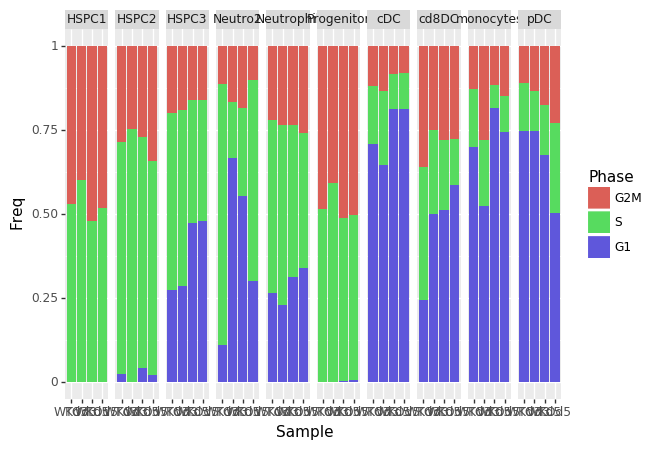

<ggplot: (8732320956709)>

In [19]:
p = (ggplot(cc, aes(x='Sample', y='Freq', fill='Phase'))
 + geom_bar( position='fill', stat="identity")
 + facet_grid('~Subset')
 + scale_x_discrete(name ='Sample', 
                    limits=['WTd3','KOd3','WTd5','KOd5'])
 + scale_fill_discrete(name="Phase",
                      #   breaks=['1','2','3'],
                      #   limits=['1','2','3'],
                         labels=['G2M','S','G1'],
                      )
)
p

In [83]:
#p.save(filename='ccScore.png', dpi=300)
p.save(filename='ccScore-1line.png', dpi=300)

/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/plotnine/ggplot.py:729: PlotnineWarning: Saving 6.4 x 4.8 in image.
  from_inches(height, units), units), PlotnineWarning)
/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/plotnine/ggplot.py:730: PlotnineWarning: Filename: ccScore-1line.png
  warn('Filename: {}'.format(filename), PlotnineWarning)


In [18]:
## use map to replace string according to dict{}
#day = {'WTd3':'3','KOd3':'3','WTd5':'5','KOd5':'5'}
#cc['Sample'].map(day)
#geno = {'WTd3':'WT','KOd3':'WT','WTd5':'KO','KOd5':'KO'}
#cc['Sample'].map(geno)

## slice WTd3 to get geno and day
cc['Geno'] = cc['Sample'].str.slice(0,2)
cc['Day'] = cc['Sample'].str.slice(3,)

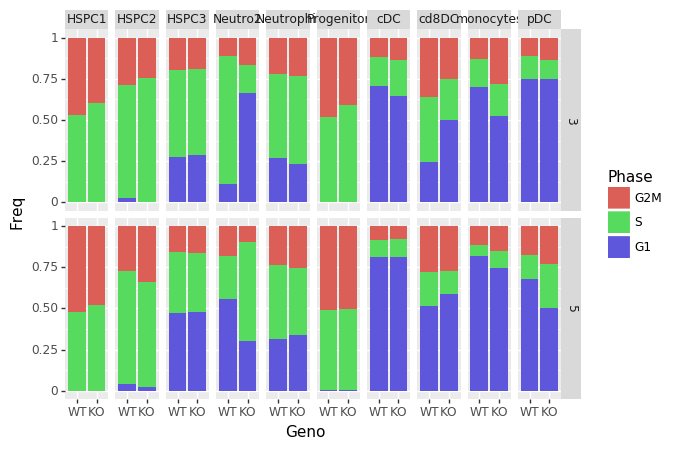

<ggplot: (8732315461945)>

In [21]:
p2 = (ggplot(cc, aes(x='Geno', y='Freq', fill='Phase'))
 + geom_bar( position='fill', stat="identity")
 + facet_grid('Day~Subset')
 + scale_x_discrete(name ='Geno', 
                     limits=['WT','KO']
                   )
 + scale_fill_discrete(name="Phase",
                      #   breaks=['1','2','3'],
                      #   limits=['1','2','3'],
                         labels=['G2M','S','G1'],
                      )
)
p2

In [13]:
p2.save(filename='ccScore-geno~day-10clu.png', dpi=300)

/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/plotnine/ggplot.py:729: PlotnineWarning: Saving 6.4 x 4.8 in image.
  from_inches(height, units), units), PlotnineWarning)
/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/plotnine/ggplot.py:730: PlotnineWarning: Filename: ccScore-geno~day-10clu.png
  warn('Filename: {}'.format(filename), PlotnineWarning)


In [15]:
cc.loc[cc['Subset'].isin(['pDC','HSPC1','HSPC2','HSPC3','HSPC4','cDC1','monocyte','cDC2'])]

,Phase,Subset,Sample,Freq
0,3,pDC,WTd3,344
1,1,pDC,WTd3,50
2,2,pDC,WTd3,67
3,3,HSPC1,WTd3,0
4,1,HSPC1,WTd3,114
...,...,...,...,...
112,1,HSPC3,KOd5,44
113,2,HSPC3,KOd5,98
114,3,cDC1,KOd5,34
115,1,cDC1,KOd5,16


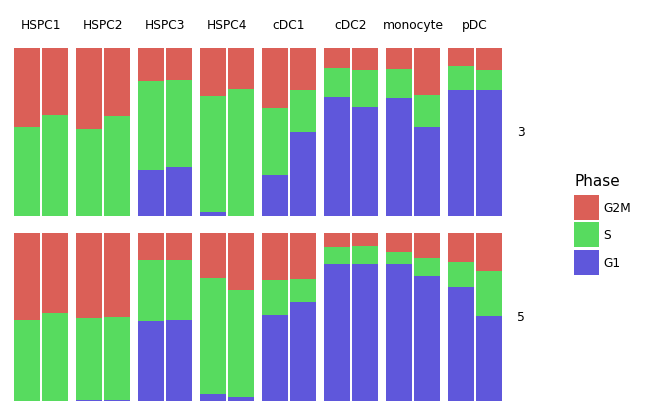

<ggplot: (8767967846853)>

In [19]:
p22 = (ggplot(cc.loc[cc['Subset'].isin(['pDC','HSPC1','HSPC2','HSPC3','cDC1','monocyte','cDC2','HSPC4'])], aes(x='Geno', y='Freq', fill='Phase'))
 + geom_bar( position='fill', stat="identity")
 + facet_grid('Day~Subset')
 + scale_x_discrete(name ='Geno', 
                     limits=['WT','KO']
                   )
 + scale_fill_discrete(name="Phase",
                      #   breaks=['1','2','3'],
                      #   limits=['1','2','3'],
                         labels=['G2M','S','G1'],
                      )
 + theme_void()
)
p22

In [20]:
p22.save(filename='ccScore-remove_neutro-void.png', dpi=300)
p22.save(filename='ccScore-remove_neutro-void.pdf')

/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/plotnine/ggplot.py:729: PlotnineWarning: Saving 6.4 x 4.8 in image.
  from_inches(height, units), units), PlotnineWarning)
/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/plotnine/ggplot.py:730: PlotnineWarning: Filename: ccScore-remove_neutro-void.png
  warn('Filename: {}'.format(filename), PlotnineWarning)
/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/plotnine/ggplot.py:729: PlotnineWarning: Saving 6.4 x 4.8 in image.
  from_inches(height, units), units), PlotnineWarning)
/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/plotnine/ggplot.py:730: PlotnineWarning: Filename: ccScore-remove_neutro-void.pdf
  warn('Filename: {}'.format(filename), PlotnineWarning)


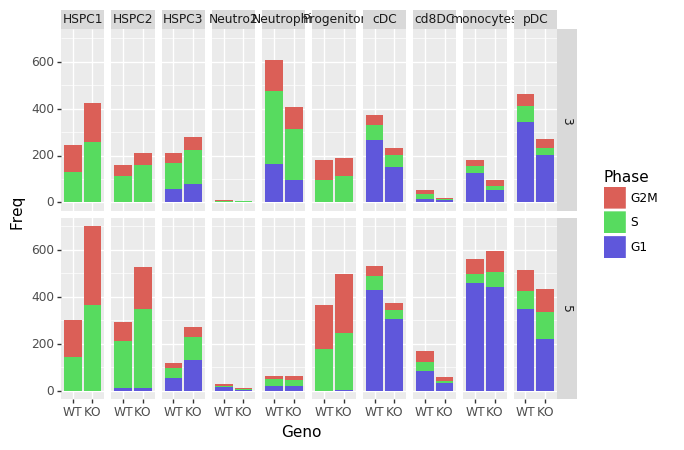

<ggplot: (8732321431273)>

In [25]:
p3 = (ggplot(cc, aes(x='Geno', y='Freq', fill='Phase'))
 + geom_bar( position='stack', stat="identity")
 + facet_grid('Day~Subset')
 + scale_x_discrete(name ='Geno', 
                     limits=['WT','KO']
                   )
 + scale_fill_discrete(name="Phase",
                      #   breaks=['1','2','3'],
                      #   limits=['1','2','3'],
                         labels=['G2M','S','G1'],
                      )
)
p3

In [89]:
p3.save(filename='ccScore_Figure/ccScore-geno~day-absolute.png', dpi=300)

/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/plotnine/ggplot.py:729: PlotnineWarning: Saving 6.4 x 4.8 in image.
  from_inches(height, units), units), PlotnineWarning)
/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/plotnine/ggplot.py:730: PlotnineWarning: Filename: ccScore_Figure/1ccScore-geno~day-absolute.png
  warn('Filename: {}'.format(filename), PlotnineWarning)


In [90]:
cc

,Phase,Subset,Sample,Freq,Geno,Day
0,3,cDC,WTd3,388,WT,3
1,1,cDC,WTd3,60,WT,3
2,2,cDC,WTd3,106,WT,3
3,3,HSPC1,WTd3,1,WT,3
4,1,HSPC1,WTd3,244,WT,3
...,...,...,...,...,...,...
67,1,Neutro,KOd5,4,KO,5
68,2,Neutro,KOd5,11,KO,5
69,3,cd8DC,KOd5,34,KO,5
70,1,cd8DC,KOd5,15,KO,5
